In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

print('All libraries imported successfully')

All libraries imported successfully


In [2]:
df = pd.read_excel(r'C:\Users\asmas\OneDrive\Desktop\E-commerce_Customer_Segmentation_2026.xlsx')
print(f'Dataset shape: {df.shape}')
print(f'Rows: {df.shape[0]}, Columns: {df.shape[1]}')
print('\nFirst few rows:')
print(df.head())
print('\nData types:')
print(df.dtypes)

Dataset shape: (50000, 53)
Rows: 50000, Columns: 53

First few rows:
   customer_id customer_segment     segment_category  age age_group  gender  \
0  CUST-000001         Consumer  High Value Inactive   70       65+    Male   
1  CUST-000002          Premium  High Value Inactive   53     45-54  Female   
2  CUST-000003         Consumer  High Value Inactive   82       65+    Male   
3  CUST-000004       Enterprise    High Value Active   18     18-24    Male   
4  CUST-000005          Premium    High Value Active   64     55-64    Male   

                country       city income_bracket education_level  ...  \
0                Canada   Winnipeg          150K+    Professional  ...   
1               Germany      Essen        25K-50K     High School  ...   
2                Mexico     Puebla       75K-100K       Bachelors  ...   
3             Singapore  Singapore          150K+         Masters  ...   
4  United Arab Emirates   Fujairah          150K+             PhD  ...   

  customer_

In [3]:
print('=' * 60)
print('PROBLEM DEFINITION')
print('=' * 60)
print(f'\nDataset: E-Commerce Customer Segmentation 2026')
print(f'Total Rows: {df.shape[0]}')
print(f'Total Columns: {df.shape[1]}')
print(f'\nTarget Variable: customer_lifetime_value_usd')
print(f'Problem Type: REGRESSION (Continuous Target)')
print(f'\nTarget Variable Statistics:')
print(f'  Mean: ${df["customer_lifetime_value_usd"].mean():.2f}')
print(f'  Min:  ${df["customer_lifetime_value_usd"].min():.2f}')
print(f'  Max:  ${df["customer_lifetime_value_usd"].max():.2f}')
print(f'  Std:  ${df["customer_lifetime_value_usd"].std():.2f}')
print('\nGoal: Predict customer lifetime value based on behavioral and demographic features')

PROBLEM DEFINITION

Dataset: E-Commerce Customer Segmentation 2026
Total Rows: 50000
Total Columns: 53

Target Variable: customer_lifetime_value_usd
Problem Type: REGRESSION (Continuous Target)

Target Variable Statistics:
  Mean: $57722.07
  Min:  $0.00
  Max:  $294634.15
  Std:  $52437.28

Goal: Predict customer lifetime value based on behavioral and demographic features


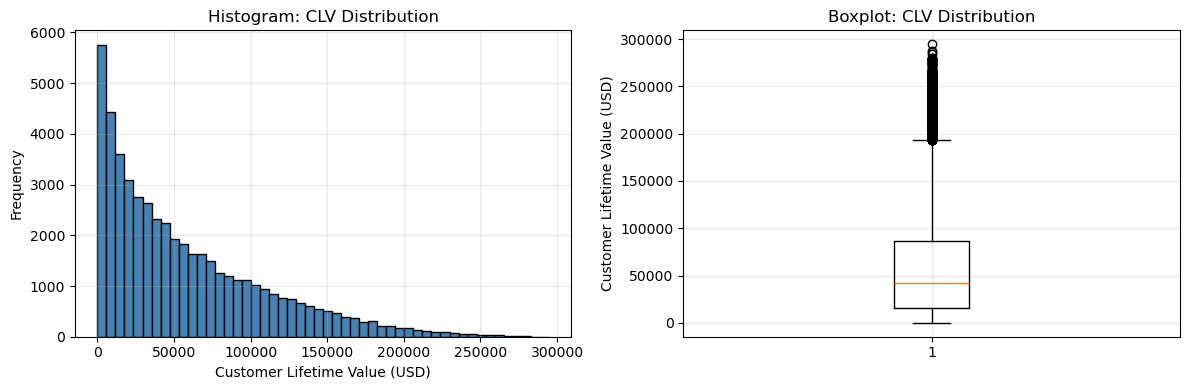

Histogram and Boxplot created successfully


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram
axes[0].hist(df['customer_lifetime_value_usd'], bins=50, color='steelblue', edgecolor='black')
axes[0].set_xlabel('Customer Lifetime Value (USD)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Histogram: CLV Distribution')
axes[0].grid(True, alpha=0.3)

# Boxplot
axes[1].boxplot(df['customer_lifetime_value_usd'], vert=True)
axes[1].set_ylabel('Customer Lifetime Value (USD)')
axes[1].set_title('Boxplot: CLV Distribution')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f'Histogram and Boxplot created successfully')

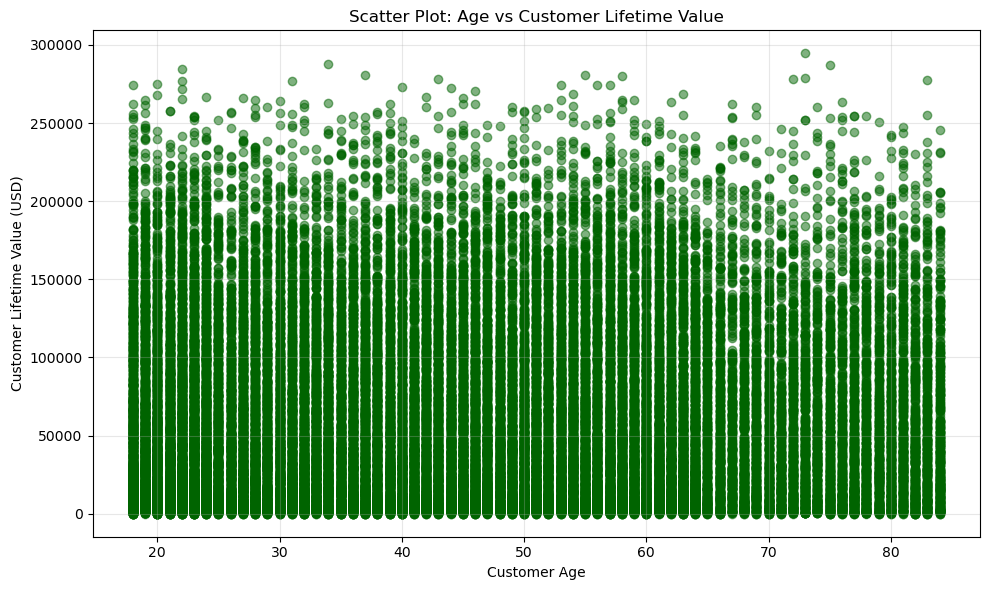

Scatter plot created successfully


In [5]:
plt.figure(figsize=(10, 6))
plt.scatter(df['age'], df['customer_lifetime_value_usd'], alpha=0.5, color='darkgreen')
plt.xlabel('Customer Age')
plt.ylabel('Customer Lifetime Value (USD)')
plt.title('Scatter Plot: Age vs Customer Lifetime Value')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('Scatter plot created successfully')

<Figure size 1000x600 with 0 Axes>

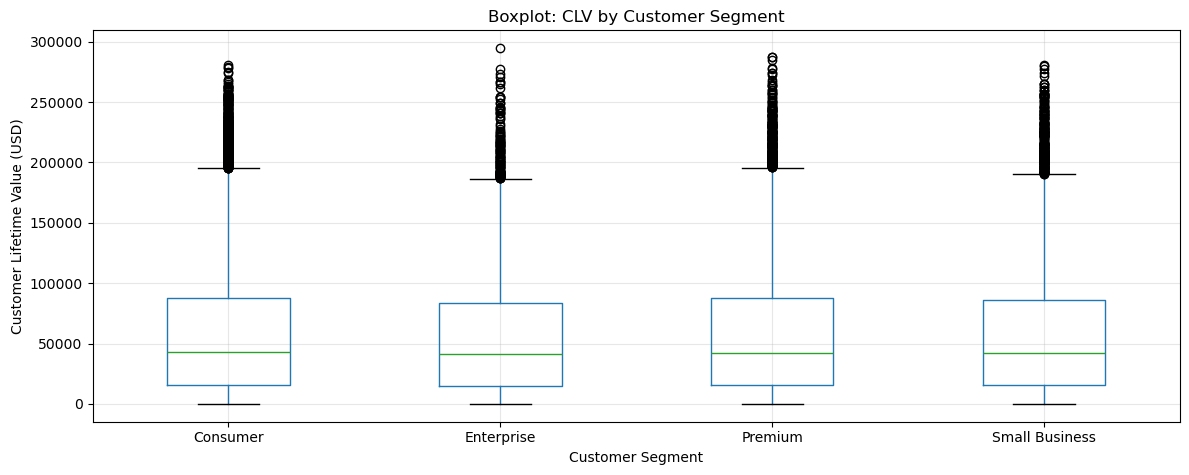

Boxplot by segment created successfully


In [6]:
plt.figure(figsize=(10, 6))
df.boxplot(column='customer_lifetime_value_usd', by='customer_segment', figsize=(12, 5))
plt.xlabel('Customer Segment')
plt.ylabel('Customer Lifetime Value (USD)')
plt.title('Boxplot: CLV by Customer Segment')
plt.suptitle('')  # Remove default title
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('Boxplot by segment created successfully')

In [7]:
print('=' * 60)
print('FEATURE SELECTION & DATA LEAKAGE CHECK')
print('=' * 60)

# Select only numerical columns
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f'\nAll numeric columns: {numerical_cols}')

# REMOVE LEAKY & USELESS COLUMNS
leaky_cols = [
    'customer_lifetime_value_usd',     # target (remove from features)
    'customer_profitability_usd',      # = CLV - CAC (leakage)
    'total_spent_usd',                 # correlation 0.97 with CLV (near-duplicate)
    'monetary_score',                  # derived from spending (leakage)
    'rfm_score',                       # derived from spending (leakage)
    'dataset_year'                     # same value for all rows (no info)
]

numerical_cols = [c for c in numerical_cols if c not in leaky_cols]

print(f'\nLeaky/useless columns removed: {leaky_cols}')
print(f'Clean numeric features: {len(numerical_cols)}')
print(f'Features: {numerical_cols}')

# Separate features and target
X = df[numerical_cols].copy()
y = df['customer_lifetime_value_usd'].copy()

print(f'\nFeature matrix shape: {X.shape}')
print(f'Target shape: {y.shape}')
print(f'Missing values in X: {X.isnull().sum().sum()}')
print(f'\nTarget Statistics:')
print(f'  Mean: ${y.mean():,.2f}')
print(f'  Median: ${y.median():,.2f}')
print(f'  Std: ${y.std():,.2f}')
print(f'  Min: ${y.min():,.2f}')
print(f'  Max: ${y.max():,.2f}')

FEATURE SELECTION & DATA LEAKAGE CHECK

All numeric columns: ['age', 'tenure_months', 'total_purchases', 'avg_order_value_usd', 'total_spent_usd', 'days_since_last_purchase', 'return_count', 'complaint_count', 'satisfaction_score', 'email_open_rate', 'click_through_rate', 'conversion_rate', 'customer_lifetime_value_usd', 'customer_acquisition_cost_usd', 'customer_profitability_usd', 'recency_score', 'frequency_score', 'monetary_score', 'rfm_score', 'churn_risk_score', 'customer_health_score', 'dataset_year']

Leaky/useless columns removed: ['customer_lifetime_value_usd', 'customer_profitability_usd', 'total_spent_usd', 'monetary_score', 'rfm_score', 'dataset_year']
Clean numeric features: 16
Features: ['age', 'tenure_months', 'total_purchases', 'avg_order_value_usd', 'days_since_last_purchase', 'return_count', 'complaint_count', 'satisfaction_score', 'email_open_rate', 'click_through_rate', 'conversion_rate', 'customer_acquisition_cost_usd', 'recency_score', 'frequency_score', 'churn_r

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('=' * 60)
print('TRAIN-TEST SPLIT')
print('=' * 60)
print(f'Training set size: {X_train.shape[0]} samples')
print(f'Test set size: {X_test.shape[0]} samples')
print(f'Total dataset size: {X.shape[0]} samples')
print(f'Train/Test ratio: {X_train.shape[0] / X.shape[0]:.1%} / {X_test.shape[0] / X.shape[0]:.1%}')
print(f'\nFeatures in training set: {X_train.shape[1]}')
print(f'Features in test set: {X_test.shape[1]}')

TRAIN-TEST SPLIT
Training set size: 40000 samples
Test set size: 10000 samples
Total dataset size: 50000 samples
Train/Test ratio: 80.0% / 20.0%

Features in training set: 16
Features in test set: 16


In [9]:
print('=' * 60)
print('FEATURE ENGINEERING & PREPROCESSING')
print('=' * 60)

# METHOD 1: Median Imputation (Handle Missing Values)
print('\nMETHOD 1: Median Imputation')
X_train_filled = X_train.fillna(X_train.median())
X_test_filled = X_test.fillna(X_train.median())
print('Why: Median is robust to outliers; preserves data distribution')
print(f'Missing values after imputation (train): {X_train_filled.isnull().sum().sum()}')
print(f'Missing values after imputation (test): {X_test_filled.isnull().sum().sum()}')

# METHOD 2: StandardScaler (Feature Scaling)
print('\nMETHOD 2: StandardScaler (Normalization)')
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_filled)
X_test_scaled = scaler.transform(X_test_filled)
print('Why: Normalizes features to mean=0, std=1; improves model convergence')
print(f'Training data shape after scaling: {X_train_scaled.shape}')
print(f'Test data shape after scaling: {X_test_scaled.shape}')

# METHOD 3: Polynomial Features (Demonstration on Subset)
print('\nMETHOD 3: Polynomial Features (Demo on First 3 Features)')
poly = PolynomialFeatures(degree=2, include_bias=False)
X_subset = X_train_filled.iloc[:, :3]
X_poly_demo = poly.fit_transform(X_subset)
print('Why: Creates interaction terms; would increase model complexity')
print(f'Original shape: {X_subset.shape}')
print(f'After polynomial transformation (degree=2): {X_poly_demo.shape}')
print('Note: Not used in final model due to dataset size (would cause overfitting)')

FEATURE ENGINEERING & PREPROCESSING

METHOD 1: Median Imputation
Why: Median is robust to outliers; preserves data distribution
Missing values after imputation (train): 0
Missing values after imputation (test): 0

METHOD 2: StandardScaler (Normalization)
Why: Normalizes features to mean=0, std=1; improves model convergence
Training data shape after scaling: (40000, 16)
Test data shape after scaling: (10000, 16)

METHOD 3: Polynomial Features (Demo on First 3 Features)
Why: Creates interaction terms; would increase model complexity
Original shape: (40000, 3)
After polynomial transformation (degree=2): (40000, 9)
Note: Not used in final model due to dataset size (would cause overfitting)


In [10]:
print('=' * 60)
print('MODEL TRAINING')
print('=' * 60)

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)

print(f'\nModel: RandomForestRegressor')
print(f'Number of trees: {model.n_estimators}')
print('Training completed successfully')

# Make predictions on both train and test sets
y_pred_train = model.predict(X_train_scaled)
y_pred_test = model.predict(X_test_scaled)

print('\nPredictions generated:')
print(f'Training predictions shape: {y_pred_train.shape}')
print(f'Test predictions shape: {y_pred_test.shape}')
print(f'Sample predictions (first 5 test): {y_pred_test[:5].round(2)}')

MODEL TRAINING

Model: RandomForestRegressor
Number of trees: 100
Training completed successfully

Predictions generated:
Training predictions shape: (40000,)
Test predictions shape: (10000,)
Sample predictions (first 5 test): [ 66528.    99308.84 126156.58   8792.73  20337.22]


In [11]:
print('=' * 60)
print('INTERPRETATION + COMMENTS')
print('=' * 60)

from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Make sure predictions exist
if 'y_pred_train' not in locals():
    print("ERROR: Model predictions not found. Please run cell 9 (MODEL TRAINING) first.")
else:
    # Calculate errors on both sets
    train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
    train_r2 = r2_score(y_train, y_pred_train)
    test_r2 = r2_score(y_test, y_pred_test)

    print(f'\nTraining Set Performance:')
    print(f'  RMSE: ${train_rmse:,.2f}')
    print(f'  R² Score: {train_r2:.4f}')

    print(f'\nTest Set Performance:')
    print(f'  RMSE: ${test_rmse:,.2f}')
    print(f'  R² Score: {test_r2:.4f}')

    print(f'\nDifference (Train RMSE - Test RMSE): ${train_rmse - test_rmse:,.2f}')

    # Interpretation
    print(f'\n--- INTERPRETATION ---')
    if train_rmse < test_rmse * 0.9:
        print('The training error is MUCH LOWER than test error.')
        print('This indicates OVERFITTING: the model memorized training data and does not generalize well.')
    else:
        print('The training and test errors are similar.')
        print('This suggests a reasonable fit.')

    print(f'\n--- BUSINESS IMPACT ---')
    print(f'Average CLV: ${y.mean():,.2f}')
    print(f'Prediction error: ${test_rmse:,.2f} ({(test_rmse/y.mean())*100:.1f}% of average)')

INTERPRETATION + COMMENTS

Training Set Performance:
  RMSE: $5,171.78
  R² Score: 0.9903

Test Set Performance:
  RMSE: $13,861.61
  R² Score: 0.9302

Difference (Train RMSE - Test RMSE): $-8,689.83

--- INTERPRETATION ---
The training error is MUCH LOWER than test error.
This indicates OVERFITTING: the model memorized training data and does not generalize well.

--- BUSINESS IMPACT ---
Average CLV: $57,722.07
Prediction error: $13,861.61 (24.0% of average)
